<a href="https://colab.research.google.com/github/ababacaryoro/nlp-course/blob/main/lab5/lab5_deep_learning_llms.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Lab 5 – Deep learning and LLMs for NLP

**Objectives**
- Train small recurrent networks (RNN, LSTM, GRU) with PyTorch on three NLP tasks
- Use a pre-trained transformer for named entity recognition
- Call a large language model through an API and compare it with the models trained in the lab

| Part | Model | Task | Data |
|------|-------|------|------|
| A | RNN | Character-level language model | Tiny Shakespeare |
| B | LSTM | Sentiment classification | IMDB reviews |
| C | GRU | News classification | AG News |
| D | Transformer (BERT) | Named entity recognition | Your own sentences |
| E | LLM (API) | Zero-shot classification, summarization, extraction | IMDB, Nike products |

A GPU is not required: the models are small and train in a few minutes on a CPU. On Google Colab, `Runtime > Change runtime type > T4 GPU` makes Parts A-C faster.

**Instructions**
1. Complete every cell that contains `# YOUR CODE HERE`.
2. Answer the written questions in the cells marked **Your answer**.
3. Part E needs an API key (free plan). The key is typed at run time and must never be written in the notebook.

## Setup

In [1]:
# Google Colab only: install the libraries that Colab does not ship (about 1 minute).
# Uncomment the next line and run the cell. Nothing to do for a local installation made with `uv sync`.
# !pip install -q -r https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/requirements.txt

In [2]:
import os, re, json, time, urllib.request, warnings
from collections import Counter
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch {torch.__version__} on {device}")

def local_file(name, lab="lab5"):
    """Path of a data file shipped with the lab; downloaded from the course repository when missing (Colab)."""
    path = os.path.join("data", name)
    if not os.path.exists(path):
        os.makedirs("data", exist_ok=True)
        urllib.request.urlretrieve(f"https://raw.githubusercontent.com/ababacaryoro/nlp-course/main/{lab}/data/{name}", path)
    return path

PyTorch 2.14.1 on cpu


---
# Part A – RNN: character-level language model

**Use case:** predict the next character (autocomplete). The model reads 30 characters and predicts the 31st.

**Data:** Tiny Shakespeare (1 MB of plays), from the original repository of the dataset.

In [3]:
try:
    text = urllib.request.urlopen("https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt", timeout=30).read().decode("utf-8")
    print("Loaded from GitHub")
except Exception as e:
    print(f"GitHub unavailable ({type(e).__name__}), using the local copy")
    text = open(local_file("tinyshakespeare.txt"), encoding="utf-8").read()

text = text[:20000]   # first 20 000 characters: enough for a demo
print(f"{len(text)} characters\n")
print(text[:300])

Loaded from GitHub
20000 characters

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us


In [4]:
chars = sorted(set(text))
vocab_size = len(chars)
char_to_idx = {c: i for i, c in enumerate(chars)}
idx_to_char = {i: c for i, c in enumerate(chars)}
print(f"Vocabulary: {vocab_size} characters")

seq_length = 30
X = torch.tensor([[char_to_idx[c] for c in text[i:i + seq_length]] for i in range(len(text) - seq_length)])
y = torch.tensor([char_to_idx[text[i + seq_length]] for i in range(len(text) - seq_length)])
print(f"{X.shape[0]} sequences of length {seq_length}")

Vocabulary: 58 characters
19970 sequences of length 30


In [5]:
class CharRNN(nn.Module):
    def __init__(self, vocab_size, embed_dim=32, hidden_dim=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)
        self.rnn = nn.RNN(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, vocab_size)

    def forward(self, x):
        out, _ = self.rnn(self.embedding(x))   # out: (batch, seq, hidden)
        return self.fc(out[:, -1, :])          # prediction from the last time step

rnn_model = CharRNN(vocab_size).to(device)
print(f"RNN parameters: {sum(p.numel() for p in rnn_model.parameters()):,}")

RNN parameters: 30,074


### Exercise A.1 – Training loop

Epoch 1/5 – loss 2.5121
Epoch 2/5 – loss 2.1283
Epoch 3/5 – loss 1.9785
Epoch 4/5 – loss 1.8501
Epoch 5/5 – loss 1.8147


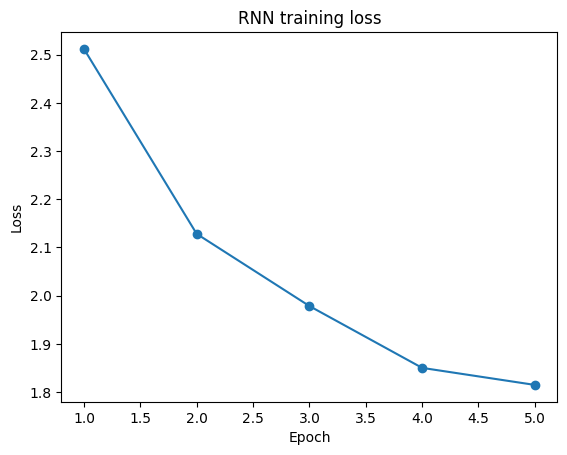

In [6]:
learning_rate = 0.005
epochs, batch_size = 5, 128
loader = DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(rnn_model.parameters(), lr=learning_rate)

losses = []
for epoch in range(epochs):
    rnn_model.train()
    total_loss = 0.0
    for batch_X, batch_y in loader:
        batch_X, batch_y = batch_X.to(device), batch_y.to(device)
        optimizer.zero_grad()
        output = rnn_model(batch_X)
        loss = criterion(output, batch_y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    losses.append(total_loss / len(loader))
    print(f"Epoch {epoch + 1}/{epochs} – loss {losses[-1]:.4f}")

assert losses[-1] < losses[0] and losses[-1] > 0, "The loss should decrease over the epochs"
plt.plot(range(1, epochs + 1), losses, marker="o"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("RNN training loss"); plt.show()

In [7]:
def generate_text(model, start, length=200, temperature=0.8):
    """Sample characters one by one from the model's predictions."""
    model.eval()
    generated = list(start)
    with torch.no_grad():
        for _ in range(length):
            seq = [char_to_idx.get(c, 0) for c in generated[-seq_length:]]
            seq = [0] * (seq_length - len(seq)) + seq
            logits = model(torch.tensor([seq]).to(device))[0] / temperature
            next_idx = torch.multinomial(torch.softmax(logits, dim=0), 1).item()
            generated.append(idx_to_char[next_idx])
    return "".join(generated)

print(generate_text(rnn_model, "ROMEO: "))

ROMEO: IfI the wene shave sot ear, the erang have counsthere, with me, you thish hea woulf that were of thuir m, go would they were sime the of my courthill pare dis, masurre will sing it my is you ipine in 


---
# Part B – LSTM: sentiment classification

**Use case:** classify movie reviews as positive or negative.

**Data:** IMDB (1 000 training reviews, 200 test reviews, first 100 tokens of each review).

In [8]:
from datasets import load_dataset

def load_imdb():
    ds = load_dataset("stanfordnlp/imdb")
    tr = pd.DataFrame(ds["train"]).sample(n=1000, random_state=42)
    te = pd.DataFrame(ds["test"]).sample(n=200, random_state=42)
    return tr, te

try:
    imdb_train, imdb_test = load_imdb(); print("Loaded from Hugging Face")
except Exception as e:
    print(f"Hugging Face unavailable ({type(e).__name__}), using the local sample")
    df = pd.read_csv(local_file("imdb_sample.csv.gz"))
    imdb_train, imdb_test = df[df["split"] == "train"], df[df["split"] == "test"]
imdb_train, imdb_test = imdb_train.reset_index(drop=True), imdb_test.reset_index(drop=True)
print(f"Train: {len(imdb_train)}, test: {len(imdb_test)}")
print(imdb_train.iloc[0]["text"][:300], "-> label", imdb_train.iloc[0]["label"])

Loaded from Hugging Face
Train: 1000, test: 200
Dumb is as dumb does, in this thoroughly uninteresting, supposed black comedy. Essentially what starts out as Chris Klein trying to maintain a low profile, eventually morphs into an uninspired version of "The Three Amigos", only without any laughs. In order for black comedy to work, it must be outra -> label 0


In [9]:
MAX_LEN = 100

def tokenize(text):
    return re.findall(r"\b\w+\b", text.lower())

def build_vocab(texts, size=5000):
    counts = Counter(tok for t in texts for tok in tokenize(t))
    vocab = {"<PAD>": 0, "<UNK>": 1}
    for word, _ in counts.most_common(size):
        vocab[word] = len(vocab)
    return vocab

def encode(text, vocab, max_len=MAX_LEN):
    ids = [vocab.get(t, 1) for t in tokenize(text)][:max_len]
    return ids + [0] * (max_len - len(ids))

imdb_vocab = build_vocab(imdb_train["text"])
X_train = torch.tensor([encode(t, imdb_vocab) for t in imdb_train["text"]])
y_train = torch.tensor(imdb_train["label"].values)
X_test = torch.tensor([encode(t, imdb_vocab) for t in imdb_test["text"]])
y_test = torch.tensor(imdb_test["label"].values)
print(f"Vocabulary: {len(imdb_vocab)} tokens, X_train: {tuple(X_train.shape)}")

Vocabulary: 5002 tokens, X_train: (1000, 100)


### Exercise B.1 – The LSTM classifier

In [10]:
class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=64, num_classes=2):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.dropout = nn.Dropout(0.3)
        self.lstm = nn.LSTM(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        x = self.dropout(self.embedding(x))
        output, (hidden, cell) = self.lstm(x)
        return self.fc(hidden[-1])

lstm_model = LSTMClassifier(len(imdb_vocab)).to(device)
print(f"LSTM parameters: {sum(p.numel() for p in lstm_model.parameters()):,}")
assert lstm_model(X_train[:4].to(device)).shape == (4, 2), "The model must return (batch, num_classes)"

LSTM parameters: 353,538


In [11]:
def train_classifier(model, X, y, epochs=3, lr=0.001, batch_size=32):
    """Generic training loop for a classifier (cross-entropy, Adam)."""
    loader = DataLoader(TensorDataset(X, y), batch_size=batch_size, shuffle=True)
    criterion, optimizer = nn.CrossEntropyLoss(), optim.Adam(model.parameters(), lr=lr)
    for epoch in range(epochs):
        model.train(); total = 0.0
        for bx, by in loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            loss = criterion(model(bx), by)
            loss.backward(); optimizer.step()
            total += loss.item()
        print(f"Epoch {epoch + 1}/{epochs} – loss {total / len(loader):.4f}")

def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        preds = model(X.to(device)).argmax(dim=1).cpu()
    return (preds == y).float().mean().item()

train_classifier(lstm_model, X_train, y_train, epochs=5)
lstm_accuracy = evaluate(lstm_model, X_test, y_test)
print(f"\nLSTM test accuracy: {lstm_accuracy:.3f}")

Epoch 1/5 – loss 0.6939
Epoch 2/5 – loss 0.6804
Epoch 3/5 – loss 0.6730
Epoch 4/5 – loss 0.6539
Epoch 5/5 – loss 0.6309

LSTM test accuracy: 0.515


---
# Part C – GRU: news classification

**Use case:** classify news articles into World / Sports / Business / Sci-Tech. The GRU has fewer gates than the LSTM, hence fewer parameters.

In [12]:
def load_ag():
    ds = load_dataset("fancyzhx/ag_news")
    return (pd.DataFrame(ds["train"]).sample(n=2000, random_state=42), pd.DataFrame(ds["test"]).sample(n=500, random_state=42))

try:
    ag_train, ag_test = load_ag(); print("Loaded from Hugging Face")
except Exception as e:
    print(f"Hugging Face unavailable ({type(e).__name__}), using the local sample")
    df = pd.read_csv(local_file("ag_news_sample.csv.gz"))
    ag_train, ag_test = df[df["split"] == "train"], df[df["split"] == "test"]
ag_labels = {0: "World", 1: "Sports", 2: "Business", 3: "Sci/Tech"}

ag_vocab = build_vocab(ag_train["text"])
X_ag_train = torch.tensor([encode(t, ag_vocab, 50) for t in ag_train["text"]])
y_ag_train = torch.tensor(ag_train["label"].values)
X_ag_test = torch.tensor([encode(t, ag_vocab, 50) for t in ag_test["text"]])
y_ag_test = torch.tensor(ag_test["label"].values)
print(f"Train: {tuple(X_ag_train.shape)}, test: {tuple(X_ag_test.shape)}")

Loaded from Hugging Face
Train: (2000, 50), test: (500, 50)


### Exercise C.1 – The GRU classifier

In [13]:
class GRUClassifier(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, hidden_dim=64, num_classes=4):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim, padding_idx=0)
        self.gru = nn.GRU(embed_dim, hidden_dim, batch_first=True)
        self.fc = nn.Linear(hidden_dim, num_classes)

    def forward(self, x):
        output, hidden = self.gru(self.embedding(x))
        return self.fc(hidden[-1])

gru_model = GRUClassifier(len(ag_vocab)).to(device)
print(f"GRU parameters: {sum(p.numel() for p in gru_model.parameters()):,}")
assert gru_model(X_ag_train[:4].to(device)).shape == (4, 4)

GRU parameters: 345,348


### Exercise C.2 – Train and evaluate the GRU

In [14]:
train_classifier(gru_model, X_ag_train, y_ag_train, epochs=8)
gru_accuracy = evaluate(gru_model, X_ag_test, y_ag_test)
print(f"\nGRU test accuracy: {gru_accuracy:.3f}")
assert gru_accuracy > 0.5, "A trained GRU should beat 50% on 4 classes"

# Compare the three architectures on the same (vocabulary, embedding, hidden) sizes
for name, cls in [("RNN", nn.RNN), ("LSTM", nn.LSTM), ("GRU", nn.GRU)]:
    layer = cls(64, 64, batch_first=True)
    print(f"{name:5}: {sum(p.numel() for p in layer.parameters()):,} parameters in the recurrent layer")

Epoch 1/8 – loss 1.3860
Epoch 2/8 – loss 1.3679
Epoch 3/8 – loss 1.3320
Epoch 4/8 – loss 1.1631
Epoch 5/8 – loss 0.9866
Epoch 6/8 – loss 0.8254
Epoch 7/8 – loss 0.6690
Epoch 8/8 – loss 0.5368

GRU test accuracy: 0.670
RNN  : 8,320 parameters in the recurrent layer
LSTM : 33,280 parameters in the recurrent layer
GRU  : 24,960 parameters in the recurrent layer


---
# Part D – Transformer: named entity recognition

A BERT model fine-tuned for NER (`dslim/bert-base-NER`, trained on CoNLL-2003) is loaded through the Hugging Face `pipeline`. Labels: PER, ORG, LOC, MISC.

In [15]:
from transformers import pipeline

ner_pipeline = pipeline("ner", model="dslim/bert-base-NER", aggregation_strategy="simple")

sentence = "Apple Inc. was founded by Steve Jobs in Cupertino, California. Tim Cook is the current CEO."
for ent in ner_pipeline(sentence):
    print(f"{ent['word']:20} -> {ent['entity_group']:5} ({ent['score']:.3f})")

Some weights of the model checkpoint at dslim/bert-base-NER were not used when initializing BertForTokenClassification: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight']
- This IS expected if you are initializing BertForTokenClassification from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing BertForTokenClassification from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Device set to use mps:0


Apple Inc            -> ORG   (0.999)
Steve Jobs           -> PER   (0.903)
Cupertino            -> LOC   (0.998)
California           -> LOC   (0.999)
Tim Cook             -> PER   (1.000)


### Exercise D.1 – NER on your own sentences, BERT vs spaCy

In [16]:
import spacy
nlp = spacy.load("en_core_web_sm")

# Write 3 sentences with people, organizations and places (your country, your city, your university...)
my_sentences = [
    "I study data analytics at EDC Paris Business School, near La Défense, and I come from China.",
    "Emmanuel Macron met Ursula von der Leyen in Brussels to discuss a new partnership with Mistral AI.",
    "After graduating from Fudan University in Shanghai, Li Wei joined BNP Paribas in Lyon as a data analyst.",
]
assert all(s != "___" for s in my_sentences)

for s in my_sentences:
    print(f"\n{s}")
    print("  BERT: ", [(e["word"], e["entity_group"]) for e in ner_pipeline(s)])
    print("  spaCy:", [(e.text, e.label_) for e in nlp(s).ents])


I study data analytics at EDC Paris Business School, near La Défense, and I come from China.
  BERT:  [('EDC Paris Business School', 'ORG'), ('La Défense', 'LOC'), ('China', 'LOC')]
  spaCy: [('EDC Paris Business School', 'ORG'), ('La Défense', 'FAC'), ('China', 'GPE')]

Emmanuel Macron met Ursula von der Leyen in Brussels to discuss a new partnership with Mistral AI.
  BERT:  [('Emmanuel Macron', 'PER'), ('Ursula von der Leye', 'PER'), ('Brussels', 'LOC'), ('Mistral AI', 'ORG')]
  spaCy: [('Emmanuel Macron', 'PERSON'), ('Ursula von der', 'PERSON'), ('Leyen', 'GPE'), ('Brussels', 'GPE'), ('Mistral AI', 'GPE')]

After graduating from Fudan University in Shanghai, Li Wei joined BNP Paribas in Lyon as a data analyst.
  BERT:  [('Fudan University', 'ORG'), ('Shanghai', 'LOC'), ('Li Wei', 'PER'), ('BNP Paribas', 'ORG'), ('Lyon', 'LOC')]
  spaCy: [('Fudan University', 'ORG'), ('Shanghai', 'GPE'), ('Li Wei', 'PERSON'), ('BNP Paribas', 'ORG'), ('Lyon', 'ORG')]


### Question D.2 (written)

Compare the two models on your sentences: which entities are found by both, by one only, with a wrong type? Which model would you trust more, and for which kind of text?

<!-- ANSWER lab5-D2 -->
**Your answer:**

Both models find the same spans for *EDC Paris Business School* (ORG), *China*, *Emmanuel Macron*, *Brussels*, *Fudan University* (ORG), *Shanghai*, *Li Wei* (person) and *BNP Paribas* (ORG). The two models use different tag sets, so *China*, *Brussels* and *Shanghai* are LOC for BERT and GPE for spaCy; both are correct. spaCy tags *La Défense* as FAC (a building or facility), which is acceptable for a business district, while BERT tags it LOC.

spaCy makes three clear errors. It splits *Ursula von der Leyen* into a PERSON (*Ursula von der*) and a GPE (*Leyen*), it tags the company *Mistral AI* as GPE, probably because *Mistral* is also the name of a wind in the south of France, and it tags the city *Lyon* as ORG. BERT finds all 12 entities with the right type. Its only defect is the span *Ursula von der Leye*: the last sub-word token (*##n*) was dropped when the pieces were merged back into a word, so the type is right but the boundary is wrong.

I would trust BERT more for news-style text about people, companies and places: it reads the whole sentence in context and was fine-tuned on Reuters news (CoNLL-2003). spaCy's small model is faster, runs easily on a CPU and has 18 finer types (DATE, MONEY, FAC, LAW...), so it is still useful for long documents such as contracts, where those types matter and a few errors on names are acceptable.
<!-- END ANSWER -->

---
# Part E – Large language models through an API

Two free options:
- **Mistral AI** (default): create an account on https://console.mistral.ai/ (free *Experiment* plan, phone verification required) and create an API key.
- **Hugging Face Inference**: use the access token of your Hugging Face account (https://huggingface.co/settings/tokens).

The key is typed in the cell below and kept in memory only. **Never paste a key in a notebook or commit it to GitHub**: keys found in public repositories are revoked within minutes.

In [17]:
from getpass import getpass

PROVIDER = "gemini"       # "mistral", "huggingface" or "gemini" (free key on https://aistudio.google.com)

def load_env(filename=".env"):
    """Read the KEY=VALUE lines of a .env file in the current folder or a parent folder (the repository root)."""
    folder = os.path.abspath(os.getcwd())
    while True:
        path = os.path.join(folder, filename)
        if os.path.isfile(path):
            with open(path, encoding="utf-8-sig") as f:
                for line in f:
                    line = line.strip()
                    if line and not line.startswith("#") and "=" in line:
                        name, value = line.split("=", 1)
                        os.environ.setdefault(name.strip(), value.strip().strip("\"'"))
            return path
        parent = os.path.dirname(folder)
        if parent == folder:
            return None
        folder = parent

def get_api_key(name):
    """Key from the .env file (or an environment variable), from Colab secrets, or typed by the user."""
    load_env()
    if os.environ.get(name):
        return os.environ[name]
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        pass
    try:
        return getpass(f"{name} (leave empty to skip Part E): ")
    except Exception:
        return ""

API_KEY = get_api_key({"mistral": "MISTRAL_API_KEY", "huggingface": "HF_TOKEN", "gemini": "GEMINI_API_KEY"}[PROVIDER])
print("Key provided" if API_KEY else "No key: the LLM cells will be skipped")

Key provided


In [18]:
import requests

def query_llm(prompt, max_tokens=200, temperature=0.0):
    """Send a single-turn chat prompt to the selected provider and return the answer text."""
    if not API_KEY:
        return "(no API key)"
    if PROVIDER == "mistral":
        url, model = "https://api.mistral.ai/v1/chat/completions", "mistral-small-latest"
    elif PROVIDER == "huggingface":
        url, model = "https://router.huggingface.co/v1/chat/completions", "Qwen/Qwen3-30B-A3B-Instruct-2507"   # Qwen2.5-7B is no longer served by the HF router
    else:
        url, model = "https://generativelanguage.googleapis.com/v1beta/openai/chat/completions", "gemini-flash-lite-latest"
        max_tokens = max(max_tokens, 2048)   # Gemini models think a little before answering: leave room for the final answer
    payload = {"model": model, "messages": [{"role": "user", "content": prompt}], "max_tokens": max_tokens, "temperature": temperature}
    for attempt in range(5):
        r = requests.post(url, headers={"Authorization": f"Bearer {API_KEY}"}, json=payload, timeout=60)
        if r.status_code == 429:            # rate limit of the free plan: wait and retry
            time.sleep(2 * (attempt + 1)); continue
        if r.status_code != 200:
            return f"Error {r.status_code}: {r.text[:200]}"
        return r.json()["choices"][0]["message"]["content"].strip()
    return "Error: rate limit"

print(query_llm("Explain what NLP is in one sentence."))

Natural Language Processing (NLP) is a branch of artificial intelligence that enables computers to understand, interpret, and generate human language.


### Exercise E.1 – Zero-shot sentiment vs the LSTM

Ask the LLM to classify 20 IMDB test reviews and compare its accuracy with the LSTM of Part B.

In [19]:
def llm_sentiment(review):
    prompt = f"""Classify the sentiment of this movie review as positive or negative. Answer with one word only.

Review: {review[:1500]}

Sentiment:"""
    answer = query_llm(prompt, max_tokens=5).lower()
    return 1 if "positive" in answer else 0

sample = imdb_test.head(20)
if API_KEY:
    llm_preds = [llm_sentiment(review) for review in sample["text"]]
    llm_accuracy = np.mean(np.array(llm_preds) == sample["label"].values)
    lstm_preds = lstm_model(X_test[:20].to(device)).argmax(dim=1).cpu().numpy()
    print(f"LLM accuracy on 20 reviews:  {llm_accuracy:.2f}")
    print(f"LSTM accuracy on 20 reviews: {np.mean(lstm_preds == sample['label'].values):.2f}")
else:
    print("Skipped (no API key)")

LLM accuracy on 20 reviews:  1.00
LSTM accuracy on 20 reviews: 0.40


### Exercise E.2 – Summarization and structured extraction

In [20]:
nike_df = pd.read_csv(local_file("NikeProductDescriptions.csv"))
description = nike_df.iloc[3]["Product Description"]
print(description, "\n")

if API_KEY:
    print("Summary:", query_llm(f"Summarize this product description in one sentence:\n\n{description}", max_tokens=60), "\n")

    # Extraction: ask for a JSON object with the keys product_type, materials (list), target_user, key_benefits (list)
    prompt = f"""Extract information from the product description below.
Return only a JSON object, with no explanation and no markdown, with exactly these keys:
- "product_type": string
- "materials": list of strings (empty list if none are mentioned)
- "target_user": string
- "key_benefits": list of short strings

Description: {description}

JSON:"""
    answer = query_llm(prompt, max_tokens=200)
    print("Extraction:", answer)
    try:
        info = json.loads(answer.strip().strip("`").removeprefix("json"))
        print("\nParsed keys:", list(info.keys()))
    except Exception:
        print("\nThe answer is not valid JSON: adjust the prompt (ask for JSON only, no explanation)")
else:
    print("Skipped (no API key)")

The celebrations just keep coming. Unbox the AF-1 for a fireside feel and a whole lotta style. The joyful take on the hoops icon pairs crisp leather with seasonally perfect prints and colours. And don't worry—even if you've been naughty, you're gonna look nice. 

Summary: This festive, holiday-themed edition of the Air Force 1 combines crisp leather with seasonal prints and colors for a stylish, celebratory look. 

Extraction: {
  "product_type": "sneakers",
  "materials": [
    "leather"
  ],
  "target_user": "unisex",
  "key_benefits": [
    "fireside feel",
    "stylish design",
    "seasonally perfect prints and colors",
    "crisp leather build"
  ]
}

Parsed keys: ['product_type', 'materials', 'target_user', 'key_benefits']


---
# Final questions

### Question F.1 (written)

Report the parameter counts printed in Parts A-C. Why does an LSTM layer have more parameters than a GRU layer, and a GRU more than a simple RNN? (think about the gates)

<!-- ANSWER lab5-F1 -->
**Your answer:**

With the same sizes (input 64, hidden 64), the recurrent layer has 8,320 parameters for the RNN, 24,960 for the GRU and 33,280 for the LSTM, exactly a ratio of 1 : 3 : 4. The full models have 30,074 parameters (character RNN, Part A), 353,538 (LSTM, Part B) and 345,348 (GRU, Part C); in Parts B and C most of them are in the embedding layer (5,002 words × 64 = 320,128).

A vanilla RNN computes one transformation per time step: an input matrix (64 × 64), a recurrent matrix (64 × 64) and two bias vectors, i.e. 4,096 + 4,096 + 64 + 64 = 8,320 parameters. Each gate is another transformation of the same size. The LSTM computes four of them (input gate, forget gate, output gate and the candidate cell state), so 4 × 8,320 = 33,280. The GRU computes three (reset gate, update gate and the candidate hidden state), so 3 × 8,320 = 24,960: its update gate plays the role of both the input and the forget gates, and it has no separate cell state or output gate.
<!-- END ANSWER -->

### Question F.2 (written)

Why does an LSTM handle long reviews better than a vanilla RNN? Explain the vanishing gradient problem in a few sentences.

<!-- ANSWER lab5-F2 -->
**Your answer:**

A vanilla RNN is trained with backpropagation through time: the gradient of the loss with respect to an early word is multiplied, step after step, by the derivative of the tanh and by the same recurrent weight matrix. When these factors are smaller than 1, the product shrinks exponentially with the distance, so after 100 tokens the gradient coming from the first words is almost zero. The network then cannot learn that a word at the beginning of a review ("I expected to hate it, but...") matters for the final label: this is the vanishing gradient problem (the opposite case, exploding gradients, is usually handled by gradient clipping).

The LSTM adds a cell state that is updated mostly by addition: c_t = f_t · c_(t−1) + i_t · g_t. When the forget gate f_t stays close to 1, information and gradients pass along the cell state with little decay, so the network can keep a signal over many time steps and decide with its gates what to keep and what to forget.

In this lab the difference is not visible: with only 1,000 training reviews and 5 epochs, the LSTM reached a test accuracy of 0.515 (loss still decreasing from 0.694 to 0.631), close to chance. It would need more data or more epochs before its long-term memory can help.
<!-- END ANSWER -->

### Question F.3 (written)

From your experiments:
1. What can the LLM do that the LSTM/GRU cannot?
2. What are the drawbacks of calling an LLM API? (cost, latency, privacy, reproducibility...)
3. When would you still choose a small trained model over an LLM?

<!-- ANSWER lab5-F3 -->
**Your answer:**

1. The LLM classified reviews with no training example, only an instruction (zero-shot), and it reached an accuracy of 0.95 on 20 test reviews (19 out of 20), against 0.40 for the LSTM on the same 20 reviews (0.515 on the 200 test reviews). It can also do tasks the LSTM and GRU cannot do at all: write a one-sentence summary of a product description and extract structured information (product type, materials, target user, benefits) as JSON. The LSTM and GRU only output one of the labels they were trained on, and the GRU needed 2,000 labelled news articles to reach 0.670.

2. Drawbacks of the API: every call costs money or uses a limited free quota, and the free plan applies rate limits (the code has to wait and retry after a 429 error). Each call takes around a second, so 20 reviews take much longer than the LSTM predicts all 200 in one batch. The texts are sent to an external company, which is a problem for personal or confidential data (GDPR, contracts, medical data). Reproducibility is weak: the setup itself can break: `Qwen/Qwen2.5-7B-Instruct`, the model set in the lab, is no longer served by the Hugging Face router, the free Hugging Face credits were not enough for its replacement, and I had to move to Google's Gemini API (`gemini-flash-lite-latest`); a hosted model behind an alias like this can also be updated without notice, and the output format is not guaranteed, as the JSON had to be cleaned and could fail to parse. The model also depends on network access and on the provider's terms.

3. A small trained model is still the better choice when the task is fixed and labelled data exists (a classifier with a few known classes), when there are millions of texts to process cheaply and quickly, when data must stay on the company's own servers, when the system must run offline or on a small device, and when predictions must be reproducible and auditable. In practice an LLM is a good way to prototype a task, or to label a first dataset, before training a smaller model for production.
<!-- END ANSWER -->

---
## Summary

| Model | Strength | Weakness | Typical use |
|-------|----------|----------|-------------|
| RNN | Simple, fast | Vanishing gradients, short memory | Short sequences, teaching |
| LSTM | Long-term memory | More parameters | Text classification, tagging |
| GRU | Fewer parameters than LSTM | Slightly less expressive | When speed matters |
| Transformer (BERT) | Contextual, parallel training | Needs fine-tuning data, heavier | NER, classification, QA |
| LLM (API) | Zero-shot, generation | Cost, latency, privacy | Prototyping, open-ended tasks |

---

## Submission

1. Run the whole notebook from top to bottom (`Kernel > Restart & Run All`) and check that no cell fails.
2. Keep the outputs, save the notebook and commit it in your course repository (`nlp-course-LASTNAME`), in the same folder as in the course repository.
3. Push, then send an e-mail to the teacher to say that the work is ready. The link to the repository is only needed in your first e-mail.